In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch import optim
from torch.utils.data import DataLoader, random_split, Subset
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path

from autoencoder import autoenc, FizeauDataset
from astropy.io import fits

from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch




In [14]:
training_frac = 0.8
N = 966
n_training = int(N*training_frac)
learning_rates = np.array([0.01, 0.001, 0.0001])
batch_size = 193
training_epochs = 100

In [15]:
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [16]:
data = Path(r"simulated_images_varied_OPD_1000")
data = sorted(data.glob("*.fits"))

dataset = FizeauDataset(data, log=True)

idxs = np.arange(0, N)
np.random.shuffle(idxs)

train_idxs = idxs[:n_training]
test_idxs = idxs[n_training:]

train_dataset = Subset(dataset, train_idxs)
test_dataset = Subset(dataset, test_idxs)

train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

print(len(dataset))

966


6
torch.Size([1, 256, 4, 4]) torch.Size([1, 1, 60, 60])
0.2697506


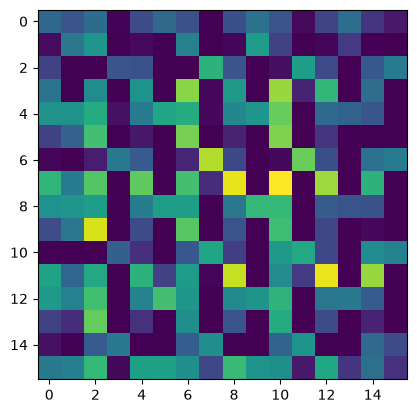

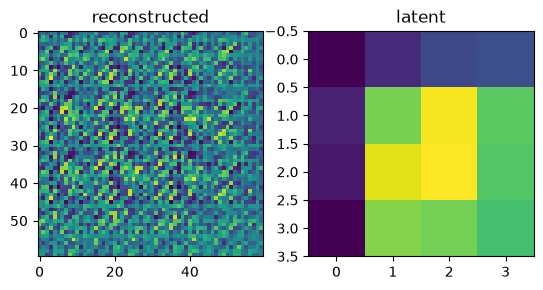

In [17]:
loss = nn.L1Loss()
model = autoenc(1)
lol, opd = train_loader.dataset[0]
lol = torch.unsqueeze(lol, dim=0)
latent, denoised, _, layer_reps = model(lol)

print(len(layer_reps))
plt.imshow(layer_reps[4][0, 0].detach().numpy())
print(latent.shape, denoised.shape)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(denoised.detach().numpy()[0, 0, :, :])
ax[1].imshow(latent.detach().numpy()[0, 0, :, :])
ax[0].set_title("reconstructed")
ax[1].set_title("latent")

loss_ = loss(lol, denoised)
print(loss_.detach().numpy())


In [18]:
loss_lr = np.zeros((3, 4*training_epochs))

for i, learning_rate in enumerate(learning_rates):
    print(f"learning rate: {learning_rate}")
    model = autoenc(1)
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)


    loss_per_epoch = []

    for epoch in range(training_epochs):
        print(f"Epoch [{epoch + 1}/{training_epochs}]")
        for batch_index, (data, _) in enumerate(tqdm(iter(train_loader))):
            # Move data and targets to the device (GPU/CPU)
            data = data.to(device)

            # Forward pass: compute the model output
            latent, reconstructed, _, _ = model(data)
            loss_ = loss(reconstructed, data)
            loss_per_epoch.append(loss_.detach().numpy())
            
            # Backward pass: compute the gradients
            optimizer.zero_grad()
            loss_.backward()

            # Optimization step: update the model parameters
            optimizer.step()

    loss_lr[i, :] = np.array(loss_per_epoch)

learning rate: 0.01
Epoch [1/100]


100%|██████████| 4/4 [00:02<00:00,  1.54it/s]


Epoch [2/100]


100%|██████████| 4/4 [00:02<00:00,  1.62it/s]


Epoch [3/100]


100%|██████████| 4/4 [00:02<00:00,  1.47it/s]


... (590 outputs left out)

Epoch [99/100]


100%|██████████| 4/4 [00:05<00:00,  1.39s/it]


Epoch [100/100]


100%|██████████| 4/4 [00:04<00:00,  1.05s/it]


0.027282018214464188 0.008773228153586388 0.016884783282876015


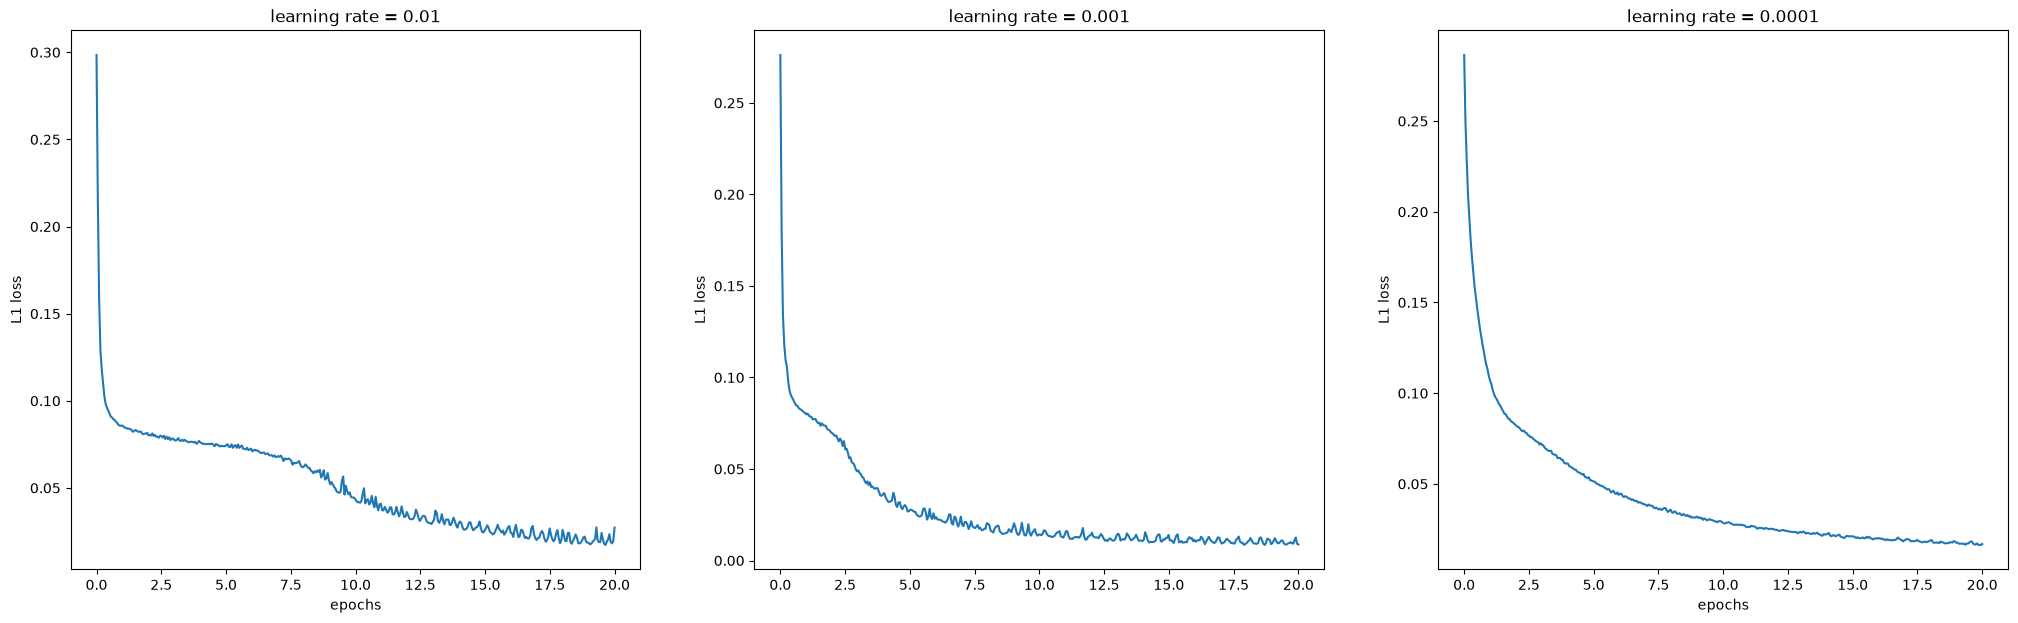

In [19]:
fig, ax = plt.subplots(1, 3)
fig.set_figheight(7)
fig.set_figwidth(25)
epochs = np.linspace(0, 20, num=400)
ax[0].plot(epochs, loss_lr[0, :])
ax[0].set_title("learning rate = 0.01")
ax[0].set_xlabel("epochs")
ax[0].set_ylabel("L1 loss")

ax[1].plot(epochs, loss_lr[1, :])
ax[1].set_title("learning rate = 0.001")
ax[1].set_ylabel("L1 loss")
ax[2].set_xlabel("epochs")

ax[2].plot(epochs, loss_lr[2, :])
ax[2].set_title("learning rate = 0.0001")
ax[2].set_ylabel("L1 loss")
ax[2].set_xlabel("epochs")

print(loss_lr[0, -1], loss_lr[1, -1], loss_lr[2, -1])

194


'\nloss_ = loss(lol, reconstructed)\nprint(loss_.detach().numpy())'

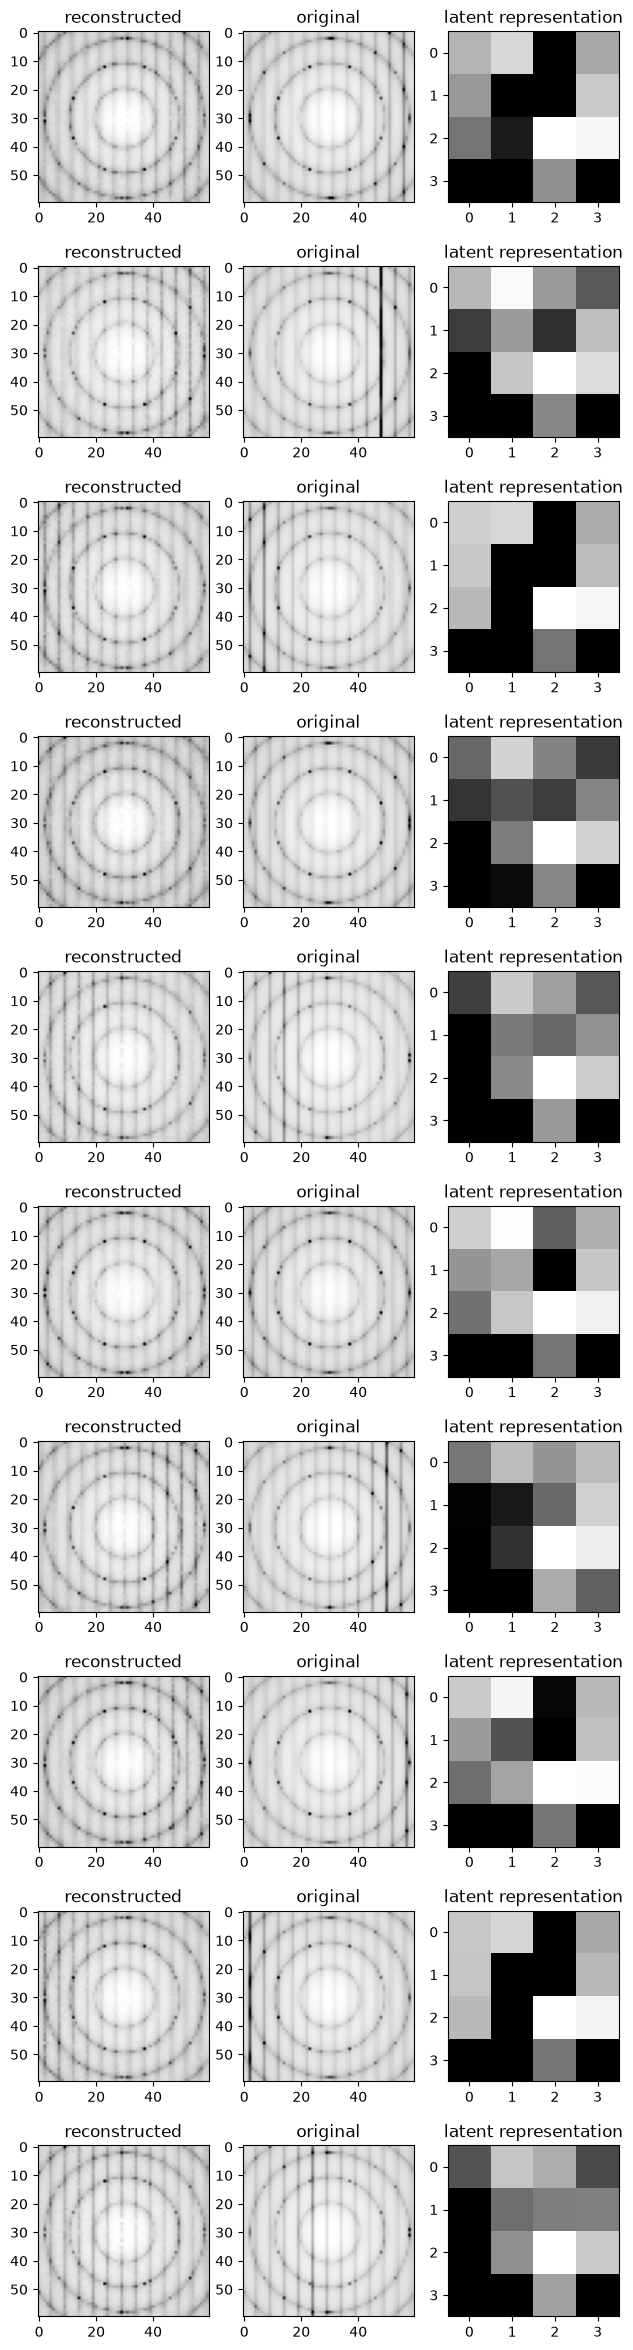

In [20]:
fig, ax = plt.subplots(10, 3)
fig.set_figheight(30)
fig.set_figwidth(7.5)
print(len(test_loader.dataset))

for i, test_data in enumerate(test_loader):
    if i == 10:
        break
    
    test_img = test_data[0]
    latent, reconstructed, _, layer_reps = model(test_img)
    norm_r = ImageNormalize(reconstructed[0, 0, :, :].detach().numpy(), interval=ZScaleInterval(), stretch=AsinhStretch())
    norm_o = ImageNormalize(test_img[0, 0, :, :].detach().numpy(), interval=ZScaleInterval(), stretch=AsinhStretch())
    norm_l = ImageNormalize(latent[0, 0, :, :].detach().numpy(), interval=ZScaleInterval(), stretch=AsinhStretch())


    ax[i, 0].imshow(reconstructed.detach().numpy()[0, 0, :, :], norm=norm_r, cmap="grey")
    ax[i, 1].imshow(test_img.detach().numpy()[0, 0, :, :], norm=norm_o, cmap="grey")
    ax[i, 2].imshow(latent.detach().numpy()[0, 0, :, :], norm=norm_l, cmap="grey")
    ax[i, 0].set_title("reconstructed")
    ax[i, 1].set_title("original")
    ax[i, 2].set_title("latent representation")

"""
loss_ = loss(lol, reconstructed)
print(loss_.detach().numpy())"""

In [21]:
lol, lol_opd = train_loader.dataset[0]
lol = torch.unsqueeze(lol, dim=0)
print(lol.shape, lol_opd)
_, out, out_hdu, _ = model(lol)
print(out[0][0].shape)


torch.Size([1, 1, 60, 60]) tensor(-0.0002)
torch.Size([60, 60])


In [22]:
out_hdu.writeto('train_lol.fits', overwrite=True)

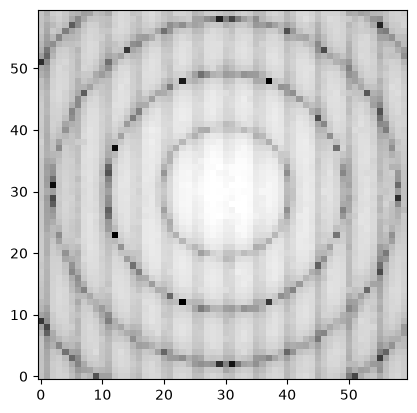

In [23]:
norm = ImageNormalize(out[0, 0, :, :].detach().numpy(), interval=ZScaleInterval(), stretch=AsinhStretch())
plt.imshow(out[0, 0, :, :].detach().numpy(), cmap='gray', norm=norm, origin='lower')


torch.Size([1, 1, 60, 60]) tensor(-0.0003)


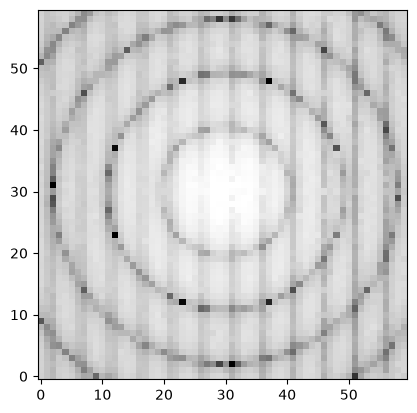

In [24]:
lol, lol_opd = test_loader.dataset[0]
lol = torch.unsqueeze(lol, dim=0)
print(lol.shape, lol_opd)
_, out, out_hdu, _ = model(lol)
out_hdu.writeto('test_lol.fits', overwrite=True)
norm = ImageNormalize(out[0,0, :, :].detach().numpy(), interval=ZScaleInterval(), stretch=AsinhStretch())
plt.imshow(out[0, 0, :, :].detach().numpy(), cmap='gray', norm=norm, origin='lower')